# R3 – Classical models: classification
**F20DL Group 5** · Requirement R3 (Abhinav, Raees)

Predict a track's popularity class: **Low (0–40)**, **Medium (41–60)** or **High (61–100)**.

| Step | What happens |
|---|---|
| Baseline | Always predict the majority class (Low) |
| Models | Logistic regression, Gaussian Naïve Bayes, Decision Tree, k-NN, Random Forest |
| Tuning | Grid search with **10-fold StratifiedGroupKFold** on the training set (grouped by `song_id`), scoring **macro-F1** |
| Selection | Tuned models re-fitted on the full training set and compared on the **validation** set |
| Feature groups | Each tuned model re-trained on all / audio / metadata / no-artist features |
| Test set | **Not used here.** Scored once at the end with `final_test()` |

**Why macro-F1?** High is only ~11% of tracks. Accuracy rewards a model that ignores High, but macro-F1 averages F1 over the three classes equally, so High counts as much as Low. For the same reason, `class_weight="balanced"` is included as a tuning option for the models that support it.

In [1]:
import json, os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import r3_common as rc

warnings.filterwarnings("ignore")
os.makedirs("results", exist_ok=True)
pd.set_option("display.float_format", "{:.3f}".format)

df, train, val, test = rc.load_data()
groups = rc.feature_groups(df)
FEATS, TARGET = groups["all"], "pop_class"
print(train[TARGET].value_counts(normalize=True).reindex(rc.CLASS_ORDER).round(3))

pop_class
Low      0.499
Medium   0.394
High     0.107
Name: proportion, dtype: float64


## 1. Baseline (majority class)

In [2]:
baseline = DummyClassifier(strategy="most_frequent").fit(train[FEATS], train[TARGET])
base_pred = baseline.predict(val[FEATS])
base_row = {"model": "Baseline (majority)", **rc.classification_metrics(val[TARGET], base_pred)}
pd.DataFrame([base_row]).set_index("model")[["accuracy", "macro_F1", "High_recall"]]

,accuracy,macro_F1,High_recall
model,,,
Baseline (majority),0.499,0.222,0.000


## 2. Tuning
- **Logistic regression** – `C` is the inverse of the L2 penalty (small C = stronger regularisation), plus class weighting.
- **Gaussian Naïve Bayes** – `var_smoothing` adds a small variance to every feature for stability. NB assumes features are independent and normally distributed within each class. The one-hot and skewed features break this, so NB is expected to be weaker. That makes it a useful contrast.
- **Decision Tree** – `max_depth`, `min_samples_leaf`, class weighting.
- **k-NN** – `n_neighbors`, `weights`. Scaled inputs.
- **Random Forest** – `max_features`, `min_samples_leaf`, class weighting. 100 trees.

k-NN and Random Forest are tuned on a stratified 20,000-row subsample (grouped CV), then re-fitted on the full training set.

In [3]:
SCORING = "f1_macro"
specs = {
    "Logistic Regression": (rc.make_pipeline(LogisticRegression(max_iter=3000), scale=True),
                            {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}, None),
    "Naive Bayes": (rc.make_pipeline(GaussianNB(), scale=False),
                    {"var_smoothing": [1e-9, 1e-5, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1]}, None),
    "Decision Tree": (rc.make_pipeline(DecisionTreeClassifier(random_state=rc.SEED), scale=False),
                      {"max_depth": [5, 10, 15, None], "min_samples_leaf": [1, 10, 50],
                       "class_weight": [None, "balanced"]}, None),
    "k-NN": (rc.make_pipeline(KNeighborsClassifier(), scale=True),
             {"n_neighbors": [3, 5, 15, 30, 50], "weights": ["uniform", "distance"]}, 20000),
    "Random Forest": (rc.make_pipeline(RandomForestClassifier(n_estimators=100, random_state=rc.SEED, n_jobs=1), scale=False),
                      {"max_features": ["sqrt", 0.33], "min_samples_leaf": [1, 5],
                       "class_weight": [None, "balanced_subsample"]}, 20000),
}
searches, tuning_rows = {}, []
for name, (pipe, grid, sub) in specs.items():
    gs, summary = rc.tune(name, pipe, grid, train, FEATS, TARGET, SCORING, subsample=sub)
    summary["cv_macroF1"] = summary.pop("cv_mean"); summary["cv_macroF1_std"] = summary.pop("cv_std")
    searches[name] = gs; tuning_rows.append(summary)
tuning_table = pd.DataFrame(tuning_rows).set_index("model")
tuning_table

Logistic Regression: best {'C': 10, 'class_weight': 'balanced'} | CV 0.6142 ± 0.0045 | 71,065 rows | 26.0s
Naive Bayes: best {'var_smoothing': 0.03} | CV 0.5976 ± 0.0088 | 71,065 rows | 10.1s
Decision Tree: best {'class_weight': None, 'max_depth': 15, 'min_samples_leaf': 50} | CV 0.6213 ± 0.0066 | 71,065 rows | 56.0s
k-NN: best {'n_neighbors': 5, 'weights': 'distance'} | CV 0.5085 ± 0.0115 | 20,000 rows | 6.6s
Random Forest: best {'class_weight': 'balanced_subsample', 'max_features': 0.33, 'min_samples_leaf': 5} | CV 0.6462 ± 0.0091 | 20,000 rows | 83.3s


,tuned_on_rows,best_params,tuning_seconds,cv_macroF1,cv_macroF1_std
model,,,,,
Logistic Regression,71065,"{""C"": 10, ""class_weight"": ""balanced""}",26.000,0.614,0.004
Naive Bayes,71065,"{""var_smoothing"": 0.03}",10.100,0.598,0.009
Decision Tree,71065,"{""class_weight"": null, ""max_depth"": 15, ""min_s...",56.000,0.621,0.007
k-NN,20000,"{""n_neighbors"": 5, ""weights"": ""distance""}",6.600,0.508,0.012
Random Forest,20000,"{""class_weight"": ""balanced_subsample"", ""max_fe...",83.300,0.646,0.009


## 3. Validation results (all features)
`train_macro_F1` is shown to spot overfitting.

In [4]:
models, val_preds, rows = {}, {}, [base_row]
for name, gs in searches.items():
    m = rc.refit_full(gs, train, FEATS, TARGET)
    p = m.predict(val[FEATS])
    models[name], val_preds[name] = m, p
    rows.append({"model": name, **rc.classification_metrics(val[TARGET], p),
                 "train_macro_F1": rc.classification_metrics(train[TARGET], m.predict(train[FEATS]))["macro_F1"]})
val_table = pd.DataFrame(rows).set_index("model")
val_table[["accuracy", "macro_F1", "train_macro_F1", "Low_F1", "Medium_F1", "High_F1", "High_precision", "High_recall"]]

,accuracy,macro_F1,train_macro_F1,Low_F1,Medium_F1,High_F1,High_precision,High_recall
model,,,,,,,,
Baseline (majority),0.499,0.222,NaN,0.666,0.000,0.000,0.000,0.000
Logistic Regression,0.654,0.613,0.615,0.776,0.558,0.506,0.379,0.758
Naive Bayes,0.651,0.601,0.598,0.721,0.625,0.458,0.478,0.440
Decision Tree,0.697,0.630,0.668,0.779,0.654,0.457,0.577,0.378
k-NN,0.621,0.538,0.997,0.716,0.571,0.327,0.417,0.269
Random Forest,0.718,0.677,0.908,0.794,0.677,0.560,0.538,0.583


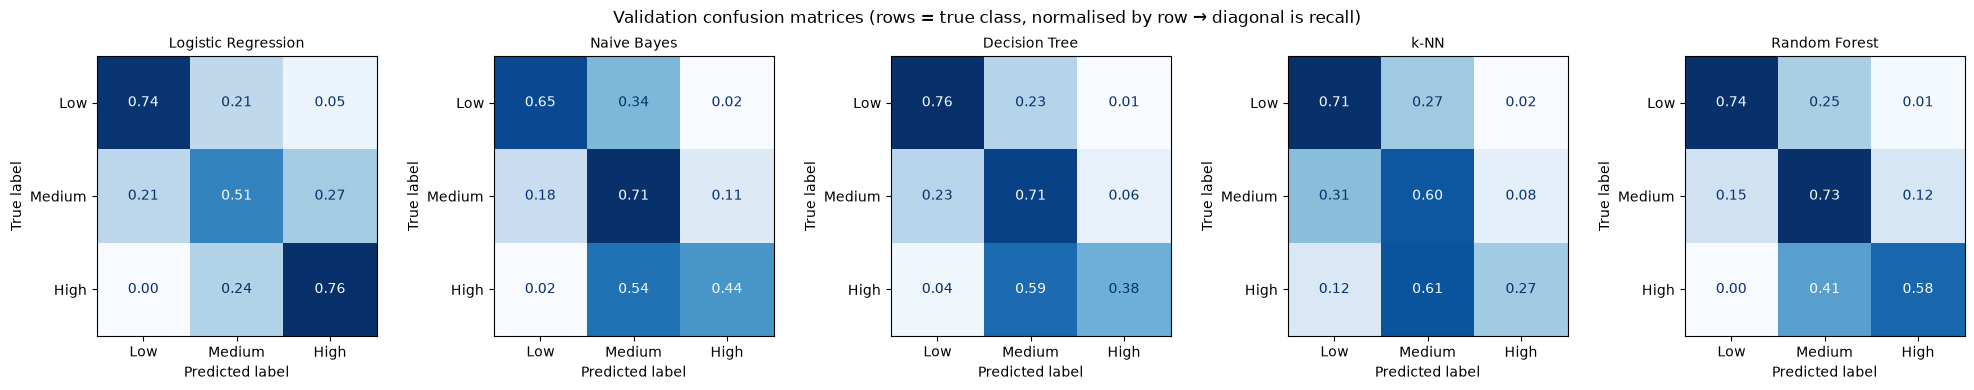

Best model on validation (macro-F1): Random Forest


,pred Low,pred Medium,pred High
true Low,5603,1902,99
true Medium,894,4387,718
true High,6,676,952


In [5]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.8))
for ax, (name, p) in zip(axes, val_preds.items()):
    ConfusionMatrixDisplay.from_predictions(val[TARGET], p, labels=rc.CLASS_ORDER, normalize="true",
                                            values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.suptitle("Validation confusion matrices (rows = true class, normalised by row → diagonal is recall)")
plt.tight_layout(); plt.savefig("results/fig_r3_cls_confusion.png", dpi=150); plt.show()
best_name = val_table.drop(index="Baseline (majority)")["macro_F1"].idxmax()
print("Best model on validation (macro-F1):", best_name)
rc.confusion(val[TARGET], val_preds[best_name])

## 4. Feature-group comparison
Same question as for regression: how much do audio features alone carry, compared with metadata and artist information?

features,all,no_artist,metadata,audio
model,,,,
Decision Tree,0.630,0.404,0.625,0.374
Logistic Regression,0.613,0.366,0.606,0.338
Naive Bayes,0.601,0.323,0.599,0.223
Random Forest,0.677,0.472,0.672,0.430
k-NN,0.538,0.406,0.624,0.383


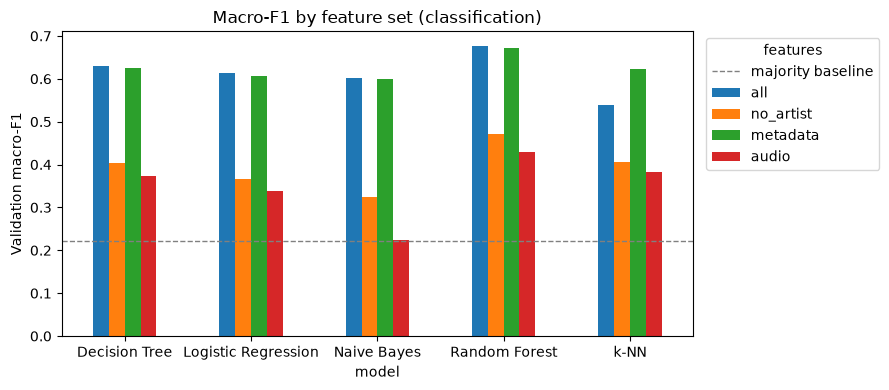

In [6]:
fg_rows = []
for gname, cols in groups.items():
    for name, gs in searches.items():
        m = clone(gs.best_estimator_)
        if "model__n_jobs" in m.get_params(): m.set_params(model__n_jobs=-1)
        m.fit(train[cols], train[TARGET])
        fg_rows.append({"features": gname, "n_cols": len(cols), "model": name,
                        **rc.classification_metrics(val[TARGET], m.predict(val[cols]))})
fg_table = pd.DataFrame(fg_rows)
piv = fg_table.pivot(index="model", columns="features", values="macro_F1")[["all", "no_artist", "metadata", "audio"]]
display(piv)
piv.plot.bar(figsize=(9, 4), rot=0)
plt.axhline(base_row["macro_F1"], color="grey", ls="--", lw=1, label="majority baseline")
plt.ylabel("Validation macro-F1"); plt.title("Macro-F1 by feature set (classification)"); plt.legend(title="features", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig("results/fig_r3_cls_feature_groups.png", dpi=150); plt.show()

## 5. Save results

In [7]:
tuning_table.to_csv("results/r3_cls_tuning.csv")
val_table.to_csv("results/r3_cls_validation.csv")
fg_table.to_csv("results/r3_cls_feature_groups.csv", index=False)
best_params = {n: {k.replace("model__", ""): v for k, v in gs.best_params_.items()} for n, gs in searches.items()}
json.dump(best_params, open("results/r3_cls_best_params.json", "w"), indent=2, default=str)
print(json.dumps(best_params, indent=2, default=str))

{
  "Logistic Regression": {
    "C": 10,
    "class_weight": "balanced"
  },
  "Naive Bayes": {
    "var_smoothing": 0.03
  },
  "Decision Tree": {
    "class_weight": null,
    "max_depth": 15,
    "min_samples_leaf": 50
  },
  "k-NN": {
    "n_neighbors": 5,
    "weights": "distance"
  },
  "Random Forest": {
    "class_weight": "balanced_subsample",
    "max_features": 0.33,
    "min_samples_leaf": 5
  }
}


## 6. Final test (run once, at the very end)
Leave `RUN_TEST = False` until the MLP (R4) is done and the final models are fixed.

In [8]:
RUN_TEST = True
if RUN_TEST:
    final = {"Baseline (majority)": DummyClassifier(strategy="most_frequent")}
    final.update({n: clone(gs.best_estimator_) for n, gs in searches.items()})
    test_table = rc.final_test(final, train, test, FEATS, TARGET, "classification")
    test_table.to_csv("results/r3_cls_TEST.csv", index=False)
    display(test_table)

,model,accuracy,macro_F1,weighted_F1,Low_precision,Low_recall,Low_F1,Medium_precision,Medium_recall,Medium_F1,High_precision,High_recall,High_F1
0,Baseline (majority),0.500,0.222,0.333,0.500,1.000,0.666,0.000,0.000,0.000,0.000,0.000,0.000
1,Logistic Regression,0.657,0.616,0.664,0.816,0.747,0.780,0.615,0.513,0.560,0.382,0.764,0.509
2,Naive Bayes,0.653,0.601,0.657,0.818,0.656,0.728,0.558,0.706,0.623,0.464,0.439,0.451
3,Decision Tree,0.696,0.624,0.693,0.801,0.760,0.780,0.608,0.704,0.653,0.555,0.364,0.439
4,k-NN,0.615,0.528,0.611,0.719,0.709,0.714,0.535,0.595,0.564,0.386,0.255,0.307
5,Random Forest,0.721,0.678,0.726,0.865,0.739,0.797,0.632,0.740,0.681,0.541,0.568,0.554
